# Comparing Bayesian synthetic-control models

This how-to fits the same geo panel, the same treatment time, and the same unit-level untreated-path estimand with three Bayesian estimators: `SyntheticControl` (`WeightedSumFitter`), `AugmentedSyntheticControl`, and `InteractiveFixedEffectsSyntheticControl`. The plots show where the post-period bands disagree. They do not rank the estimators by pre-period fit.

Posterior bands are Bayesian intervals only for the full model that produced them. A `SyntheticControl` band is not an augmented posterior. None of the bands claims nominal coverage.

The cross-model note is [Comparing Bayesian synthetic-control models](../knowledgebase/comparing-bayesian-synthetic-control.md). Specifications stay on [Augmented synthetic control](../knowledgebase/augmented-synthetic-control.md) and [Interactive fixed-effects synthetic control](../knowledgebase/interactive-fixed-effects.md). The inside-or-outside record is the [known-truth report](../knowledgebase/bayesian_synthetic_control_known_truth_report.md). This notebook does not reimplement that study.

## Shared geo scenario

The panel is `load_data("geolift1")`: weekly sales for European countries, with Denmark refurbished from the start of 2022. The estimand is Denmark's untreated sales path over the shared post window, and the contrast of observed Denmark sales with that path.

The comparison uses one shared window: eight weeks immediately before `treatment_time`, and four weeks at or after it. Donor choice uses pre-window correlation with Denmark only. Treated post-window sales are not used to choose donors, sample length, or a preferred model.

In [1]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd

import causalpy as cp
from causalpy.experiments.augmented_synthetic_control import AugmentedSyntheticControl
from causalpy.experiments.interactive_fixed_effects import (
    InteractiveFixedEffectsSyntheticControl,
)
from causalpy.experiments.synthetic_control import SyntheticControl
from causalpy.pymc_models import WeightedSumFitter
from causalpy.tests.known_truth_panels import donor_shock

SAMPLE = {
    "draws": 40,
    "tune": 40,
    "chains": 1,
    "cores": 1,
    "random_seed": 1240,
    "progressbar": False,
    "compute_convergence_checks": False,
}
TREATED = "Denmark"
TREATMENT_TIME = pd.Timestamp("2022-01-01")
N_PRE = 8
N_POST = 4

## One panel, one treatment definition

Rows strictly before `treatment_time` are the pre-window. Rows at or after it are the post-window. The same donor list is passed to all three estimators.

In [2]:
raw = cp.load_data("geolift1")
raw["time"] = pd.to_datetime(raw["time"])
raw = raw.set_index("time").sort_index()

pre_index = raw.index[raw.index < TREATMENT_TIME][-N_PRE:]
post_index = raw.index[raw.index >= TREATMENT_TIME][:N_POST]
window = raw.loc[pre_index.union(post_index)]

pre = window.loc[window.index < TREATMENT_TIME]
donors = [
    name for name in pre.columns if name != TREATED and pre[name].corr(pre[TREATED]) > 0
]
panel = window[donors + [TREATED]].copy()
panel.index.name = "obs_ind"
print("shared window", panel.index.min().date(), "to", panel.index.max().date())
print("donors", donors)
print("post rows", int((panel.index >= TREATMENT_TIME).sum()))

shared window 2021-11-07 to 2022-01-23
donors ['Austria', 'Belgium', 'Czech_Republic', 'Hungary']
post rows 4


## Fits

Each call uses the same frame, `treatment_time`, donors, and treated unit. The short sample is for this notebook. It is not the known-truth report's sample, and it is not a coverage study.

`SyntheticControl` bands below come from `WeightedSumFitter`. `AugmentedSyntheticControl` bands come from the joint posterior of `counterfactual` and `treatment_effect`. Interactive fixed-effects bands come from `predictions_post` and `impact_post` after marginalizing `shrinkage_state`.

In [3]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)
    weighted = SyntheticControl(
        panel,
        TREATMENT_TIME,
        donors,
        [TREATED],
        model=WeightedSumFitter(sample_kwargs=SAMPLE),
    ).fit()

augmented = AugmentedSyntheticControl(
    panel,
    TREATMENT_TIME,
    donors,
    [TREATED],
).fit(SAMPLE)

interactive = InteractiveFixedEffectsSyntheticControl(
    panel,
    TREATMENT_TIME,
    donors,
    [TREATED],
    max_factors=4,
).fit(**SAMPLE)

print("augmented posterior names", sorted(augmented.idata.posterior.data_vars))
print("interactive pre-period score", interactive.result.score.to_dict())
print(
    "shrinkage_state factors",
    list(interactive.result.shrinkage_state.coords["factors"].values),
)

augmented posterior names ['base_weights', 'counterfactual', 'prognostic_coefficients', 'tau', 'treatment_effect']
interactive pre-period score {'unit_0_r2': 0.3753144681222683, 'unit_0_r2_std': 0.16335169223539134}
shrinkage_state factors [np.str_('f0'), np.str_('f1'), np.str_('f2'), np.str_('f3')]


## Pre-period fit

These series use only the pre-window. The weighted-sum and interactive fixed-effects lines are posterior means of `predictions_pre`. The augmented line is the donor path at the posterior mean of `base_weights`. A smaller gap here is a fit diagnostic. It does not identify the causal effect.

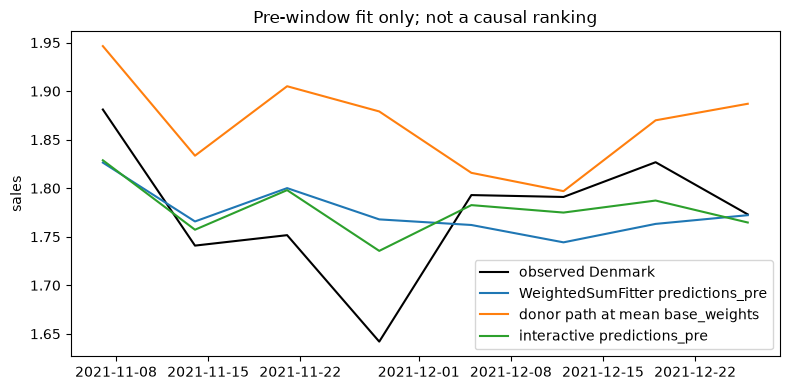

In [4]:
pre_time = panel.index[panel.index < TREATMENT_TIME]
observed_pre = panel.loc[pre_time, TREATED]

weighted_pre = (
    weighted.result.predictions_pre.sel(treated_units=TREATED)
    .mean(("chain", "draw"))
    .values
)
interactive_pre = (
    interactive.result.predictions_pre.sel(treated_units=TREATED)
    .mean(("chain", "draw"))
    .values
)
weights = (
    augmented.idata.posterior["base_weights"]
    .sel(treated_units=TREATED)
    .mean(("chain", "draw"))
    .values
)
augmented_pre = panel.loc[pre_time, donors].to_numpy() @ weights

figure, axis = plt.subplots(figsize=(8, 4))
axis.plot(pre_time, observed_pre, color="black", label="observed Denmark")
axis.plot(pre_time, weighted_pre, label="WeightedSumFitter predictions_pre")
axis.plot(pre_time, augmented_pre, label="donor path at mean base_weights")
axis.plot(pre_time, interactive_pre, label="interactive predictions_pre")
axis.set_ylabel("sales")
axis.set_title("Pre-window fit only; not a causal ranking")
axis.legend()
figure.tight_layout()

## Post-period counterfactual bands and effects

Each band is the 3–97% posterior interval of the named series from the full fitted model. The weighted-sum band is not labeled as an augmented posterior. Agreement among the three means is not identification.

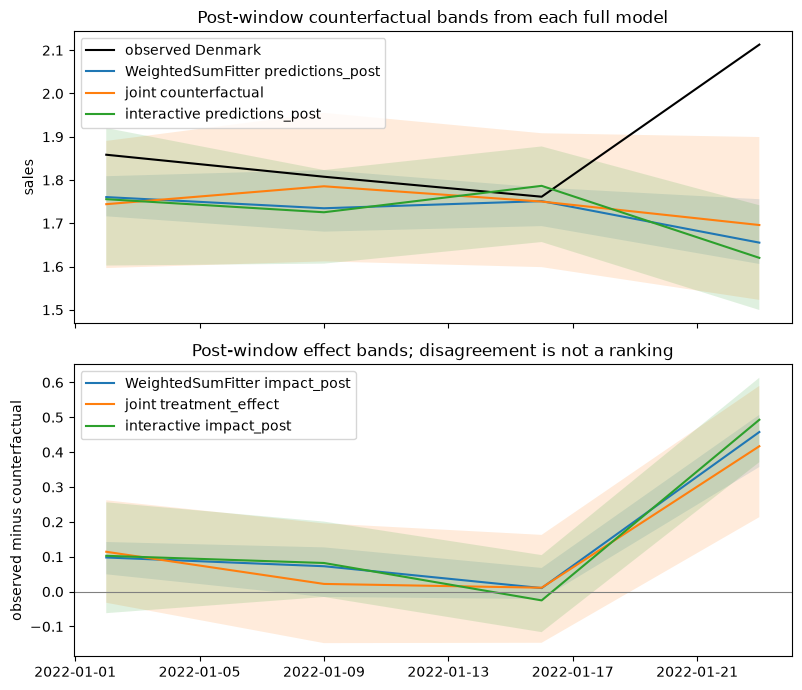

In [5]:
post_time = panel.index[panel.index >= TREATMENT_TIME]
observed_post = panel.loc[post_time, TREATED]


def band(draws):
    reduced = draws.sel(treated_units=TREATED)
    return (
        reduced.mean(("chain", "draw")),
        reduced.quantile(0.03, dim=("chain", "draw")),
        reduced.quantile(0.97, dim=("chain", "draw")),
    )


counterfactuals = {
    "WeightedSumFitter predictions_post": band(weighted.result.predictions_post),
    "joint counterfactual": band(augmented.idata.posterior["counterfactual"]),
    "interactive predictions_post": band(interactive.result.predictions_post),
}
effects = {
    "WeightedSumFitter impact_post": band(weighted.result.impact_post),
    "joint treatment_effect": band(augmented.idata.posterior["treatment_effect"]),
    "interactive impact_post": band(interactive.result.impact_post),
}

figure, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True)
axes[0].plot(post_time, observed_post, color="black", label="observed Denmark")
for label, (mean, low, high) in counterfactuals.items():
    axes[0].plot(post_time, mean, label=label)
    axes[0].fill_between(post_time, low, high, alpha=0.15)
axes[0].set_ylabel("sales")
axes[0].set_title("Post-window counterfactual bands from each full model")
axes[0].legend()

for label, (mean, low, high) in effects.items():
    axes[1].plot(post_time, mean, label=label)
    axes[1].fill_between(post_time, low, high, alpha=0.15)
axes[1].axhline(0.0, color="gray", linewidth=0.8)
axes[1].set_ylabel("observed minus counterfactual")
axes[1].set_title("Post-window effect bands; disagreement is not a ranking")
axes[1].legend()
figure.tight_layout()

## Factor diagnostic the interactive model already exposes

`shrinkage_state` is one positive scale per factor, up to `max_factors`. It is not a selected rank. `score` is the pre-period prediction error. Neither quantity is a causal validity flag.

pre-period score {'unit_0_r2': 0.3753144681222683, 'unit_0_r2_std': 0.16335169223539134}


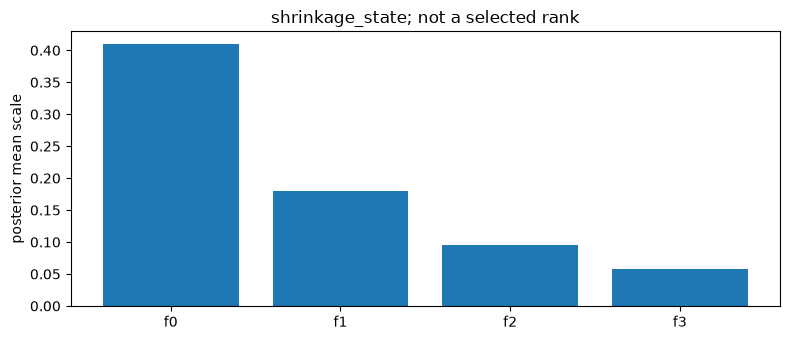

In [6]:
scales = interactive.result.shrinkage_state
scale_mean = scales.mean(("chain", "draw"))
figure, axis = plt.subplots(figsize=(8, 3.5))
axis.bar(list(scale_mean.coords["factors"].values), scale_mean.values)
axis.set_ylabel("posterior mean scale")
axis.set_title("shrinkage_state; not a selected rank")
figure.tight_layout()
print("pre-period score", interactive.result.score.to_dict())

## Failure mode: donor shock

`donor_shock` is a known-truth panel, not another geo fit. The treated pre-period is an exact convex combination of the donors, and the planted effect is zero. One donor's post-period path leaves the path that generated the treated unit's untreated trajectory. The figure marks that jump. It does not refit the coverage study.

The [known-truth report](../knowledgebase/bayesian_synthetic_control_known_truth_report.md) records the failure: at every post time, `SyntheticControl` intervals for `predictions_post` and `impact_post`, and joint `AugmentedSyntheticControl` intervals for `counterfactual` and `treatment_effect`, exclude the planted untreated path and the planted effect. A closer pre-period fit does not repair the post-period donor shock. Those 0/1 flags are not a coverage rate, and this notebook does not promise nominal coverage.

planted post effect [0.0, 0.0, 0.0, 0.0]


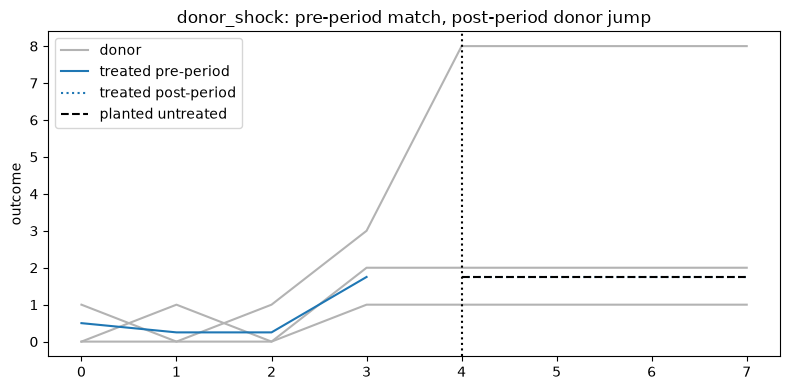

In [7]:
shock = donor_shock
shock_time = shock.data.index
pre_shock = shock_time < shock.treatment_time
post_shock = shock_time >= shock.treatment_time
planted = shock.untreated["treated"]

figure, axis = plt.subplots(figsize=(8, 4))
for name in shock.control_units:
    axis.plot(
        shock_time,
        shock.data[name],
        color="0.7",
        label="donor" if name == "c0" else None,
    )
axis.plot(
    shock_time[pre_shock],
    shock.data.loc[pre_shock, "treated"],
    color="C0",
    label="treated pre-period",
)
axis.plot(
    shock_time[post_shock],
    shock.data.loc[post_shock, "treated"],
    color="C0",
    linestyle=":",
    label="treated post-period",
)
axis.plot(
    shock_time[post_shock],
    planted.loc[post_shock],
    color="black",
    linestyle="--",
    label="planted untreated",
)
axis.axvline(shock.treatment_time, color="black", linestyle=":")
axis.set_ylabel("outcome")
axis.set_title("donor_shock: pre-period match, post-period donor jump")
axis.legend()
figure.tight_layout()
print("planted post effect", shock.effect.loc[post_shock, "treated"].tolist())

## What the comparison does not say

The three post-window bands can disagree because the models condition on different untreated structure: a simplex-weighted donor path, that path plus a donor prognostic correction, or a shrunk factor mean. Overlap of those bands is not evidence that the shared assumption is true. A smaller pre-window gap is not a reason to prefer an estimator.

The augmented fit plotted above uses `base_weights`, `counterfactual`, `treatment_effect`, and `tau`. It does not read a separate correction series, and it does not treat a missing extrapolation summary as a defect. Interactive fixed-effects intervals marginalize `shrinkage_state`. They are not conditional on a selected rank.